# Decision Tree Classification — Social Network Ads

Same dataset and target as the Naive Bayes notebook — **Age** and **EstimatedSalary** predicting **Purchased** — so you can directly compare how a Decision Tree's decision boundary differs from Naive Bayes'.

`Social_Network_Ads.csv` should sit alongside this notebook.

In [1]:
# 1. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    confusion_matrix, accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

sns.set_style("whitegrid")

## 2. Load the Dataset

In [2]:
df = pd.read_csv("Social_Network_Ads.csv")
print(df.shape)
df.head()

(400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


## 3. Select Features and Target, Train/Test Split
Note: unlike Naive Bayes or KNN, decision trees split on one feature at a time using thresholds, so **feature scaling is not required** — the tree finds the same splits whether Age is in years or standardized units.

In [3]:
X = df[["Age", "EstimatedSalary"]].values
y = df["Purchased"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 300  Test size: 100


## 4. Fit a Decision Tree
We start with a shallow tree (`max_depth=4`) on purpose. An unrestricted tree will keep splitting until every training point is perfectly classified — memorizing noise rather than learning a general rule (overfitting). Limiting depth is one of the simplest ways to control that.

In [4]:
model = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=0)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 5. Evaluate the Model

In [5]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}\n")
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Not Purchased", "Purchased"]))

Accuracy: 0.880

Classification report:
               precision    recall  f1-score   support

Not Purchased       0.92      0.89      0.90        64
    Purchased       0.82      0.86      0.84        36

     accuracy                           0.88       100
    macro avg       0.87      0.88      0.87       100
 weighted avg       0.88      0.88      0.88       100



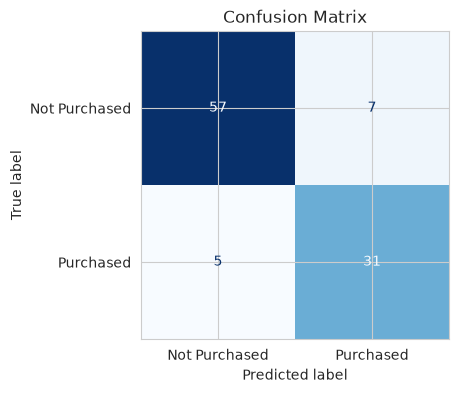

In [6]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Purchased", "Purchased"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix")
plt.show()

## 6. Visualize the Tree Itself
This is the big advantage decision trees have over Naive Bayes: you can literally read off the decision logic. Each box shows the split condition, the entropy (impurity) at that node, how many training samples reached it, and the predicted class.

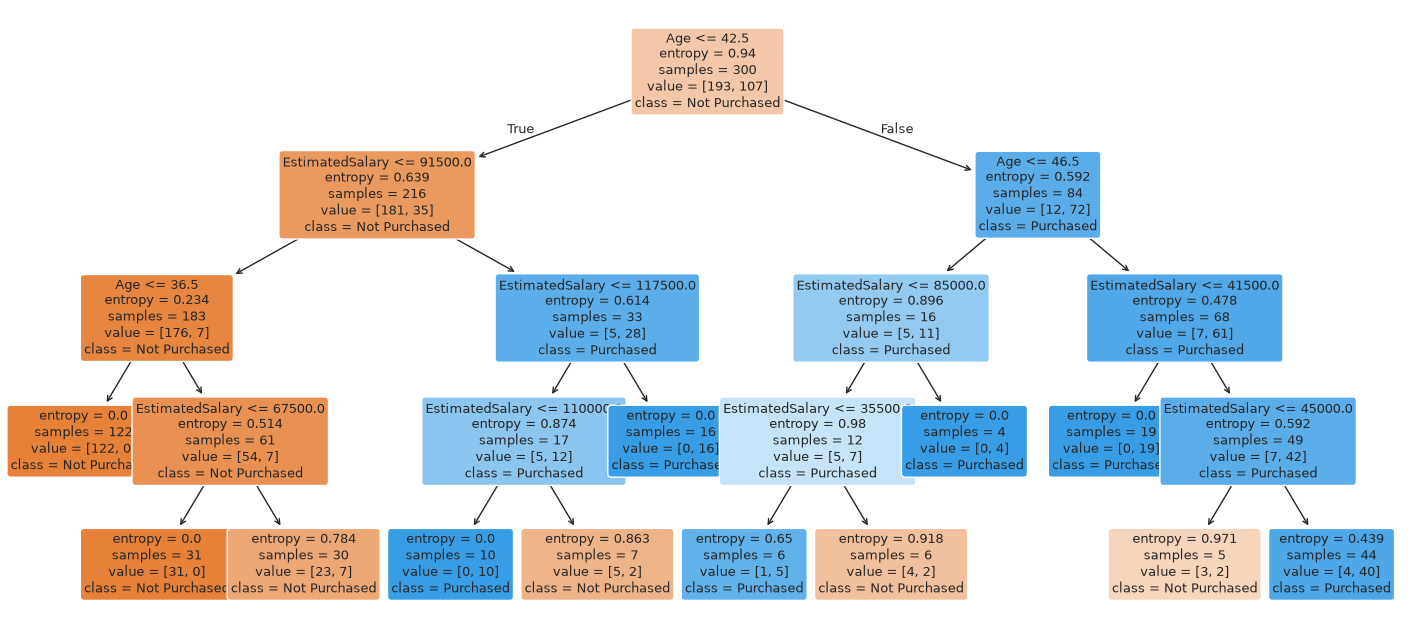

In [7]:
plt.figure(figsize=(18, 8))
plot_tree(
    model,
    feature_names=["Age", "EstimatedSalary"],
    class_names=["Not Purchased", "Purchased"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.show()

## 7. Feature Importance
How much each feature contributed to reducing impurity across all splits in the tree.

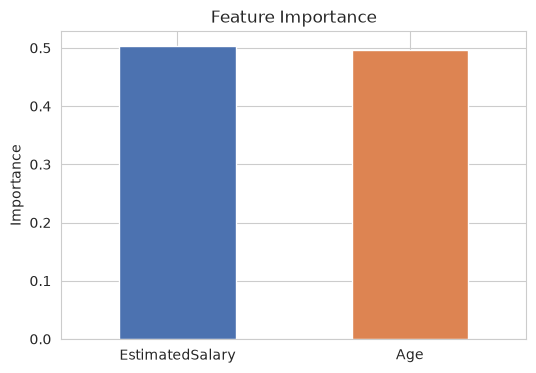

EstimatedSalary    0.503899
Age                0.496101
dtype: float64

In [8]:
importances = pd.Series(model.feature_importances_, index=["Age", "EstimatedSalary"])
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(6, 4))
importances.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.xticks(rotation=0)
plt.show()

importances

## 8. Visualize the Decision Boundary
Notice the shape: unlike Naive Bayes' smooth curved regions, a decision tree's boundary is made of **straight, axis-aligned rectangular splits** — because every split is "is this one feature above/below some threshold?".

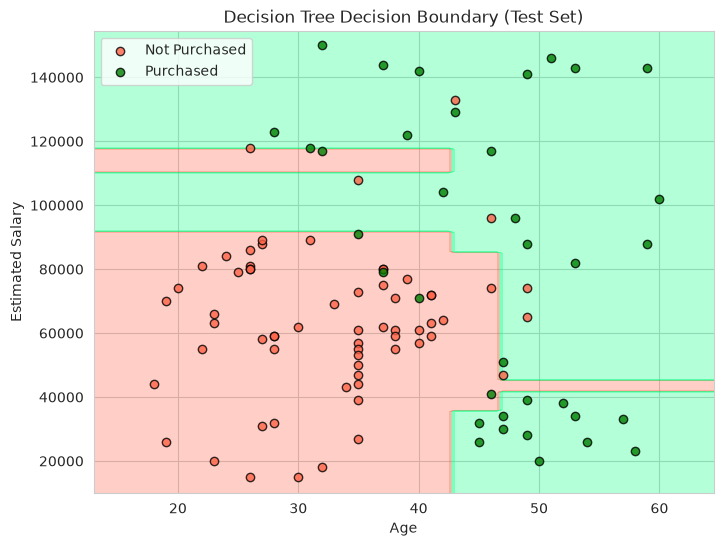

In [9]:
from matplotlib.colors import ListedColormap

X_set, y_set = X_test, y_test

X1, X2 = np.meshgrid(
    np.arange(X_set[:, 0].min() - 5, X_set[:, 0].max() + 5, 0.5),
    np.arange(X_set[:, 1].min() - 5000, X_set[:, 1].max() + 5000, 500)
)
Z = model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap=ListedColormap(("tomato", "springgreen")))

for cls, color, label in zip([0, 1], ["tomato", "green"], ["Not Purchased", "Purchased"]):
    mask = y_set == cls
    plt.scatter(X_set[mask, 0], X_set[mask, 1], c=color, edgecolor="k", label=label, alpha=0.8)

plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.title("Decision Tree Decision Boundary (Test Set)")
plt.legend()
plt.show()

## 9. Effect of Tree Depth (Overfitting Check)
A quick demonstration of the bias-variance tradeoff: as `max_depth` increases, training accuracy keeps climbing (or hits 100%), but test accuracy peaks and then flattens or drops — the tree is starting to memorize training noise instead of learning general patterns.

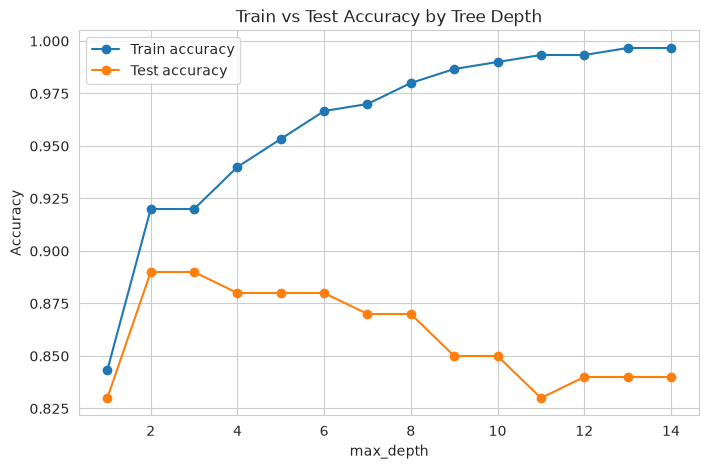

In [10]:
depths = range(1, 15)
train_scores, test_scores = [], []

for d in depths:
    dt = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
    dt.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, dt.predict(X_train)))
    test_scores.append(accuracy_score(y_test, dt.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker="o", label="Train accuracy")
plt.plot(depths, test_scores, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy by Tree Depth")
plt.legend()
plt.show()

## Interpretation
- **Tree diagram**: read top-down — each internal node is a yes/no question about Age or EstimatedSalary; leaves are the final predictions.
- **Feature importance**: whichever feature appears in splits higher up (closer to the root) and reduces impurity more tends to dominate — for this dataset, Age typically comes out as the stronger predictor.
- **Decision boundary**: the rectangular, step-shaped regions are the visual signature of a decision tree — very different from Naive Bayes' smooth curves. This also hints at what a tree struggles with: relationships that are naturally diagonal or curved need many small rectangular splits to approximate, whereas Naive Bayes or logistic regression might capture them more directly.
- **Depth plot**: use this to pick `max_depth` for a real project — you want the depth where test accuracy is near its peak, not necessarily where it's highest on the training data.